In [2]:
import sys

print("Python version:", sys.version)
print("Environment path:", sys.executable)


Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Environment path: c:\Users\abdul\Documents\BIA\bia_py_env\Scripts\python.exe


In [1]:
import sys

print("Environment path:", sys.executable)

Environment path: c:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction\ecommerce_env\Scripts\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
from pathlib import Path

print("Current directory:", Path.cwd())

Current directory: c:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction


In [4]:
df = pd.read_csv(r"C:\Users\abdul\Documents\BIA\ML\Ecommerce_Delivery_Prediction\datasets\E_Commerce.csv")

df.head()

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10999
Columns: 12


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
dtypes: int64(8), str(4)
memory usage: 1.0 MB


In [7]:
df.isnull().sum()

ID                     0
Warehouse_block        0
Mode_of_Shipment       0
Customer_care_calls    0
Customer_rating        0
Cost_of_the_Product    0
Prior_purchases        0
Product_importance     0
Gender                 0
Discount_offered       0
Weight_in_gms          0
Reached.on.Time_Y.N    0
dtype: int64

In [8]:
df.duplicated().sum()


np.int64(0)

Reached.on.Time_Y.N
1    6563
0    4436
Name: count, dtype: int64
Reached.on.Time_Y.N
1    59.669061
0    40.330939
Name: proportion, dtype: float64


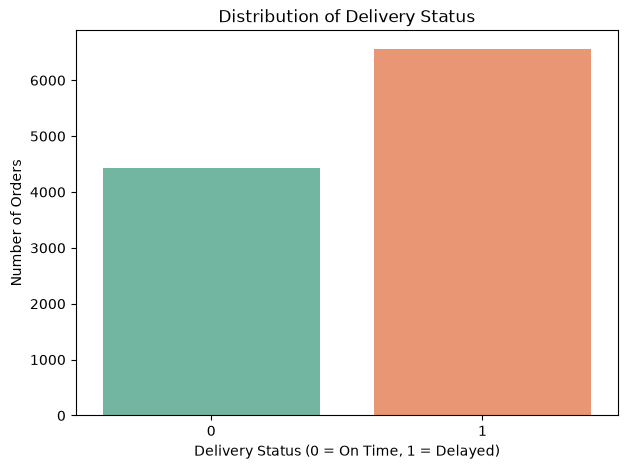

In [9]:
target = "Reached.on.Time_Y.N"

print(df[target].value_counts())
print(df[target].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target,
    hue=target,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Delivery Status")
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Number of Orders")
plt.show()

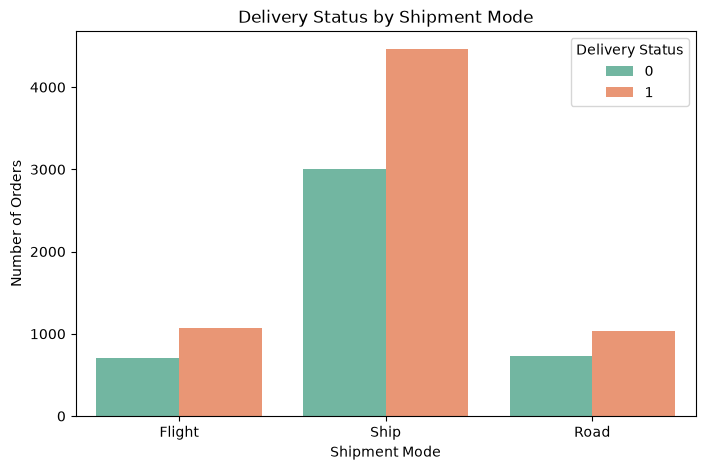

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Mode_of_Shipment",
    hue=target,
    palette="Set2"
)

plt.title("Delivery Status by Shipment Mode")
plt.xlabel("Shipment Mode")
plt.ylabel("Number of Orders")
plt.legend(title="Delivery Status")
plt.show()

Warehouse_block
B    60.229133
F    59.847245
D    59.760087
C    59.683579
A    58.647027
Name: Reached.on.Time_Y.N, dtype: float64


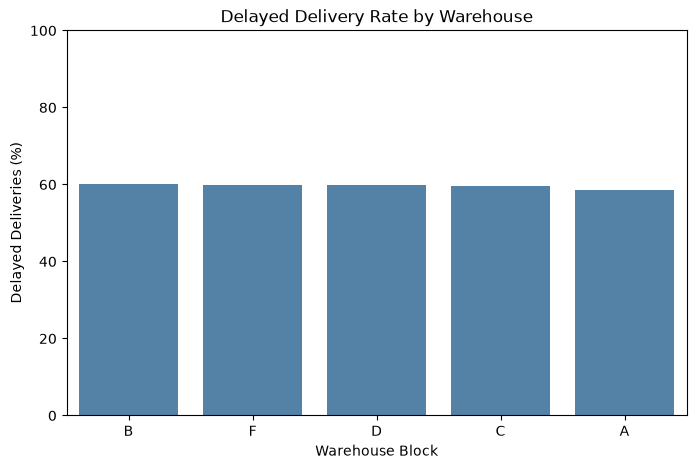

In [11]:
warehouse_delay = (
    df.groupby("Warehouse_block")["Reached.on.Time_Y.N"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(warehouse_delay)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=warehouse_delay.index,
    y=warehouse_delay.values,
    color="steelblue"
)

plt.title("Delayed Delivery Rate by Warehouse")
plt.xlabel("Warehouse Block")
plt.ylabel("Delayed Deliveries (%)")
plt.ylim(0, 100)
plt.show()

Mode_of_Shipment
Flight    60.157569
Ship      59.756098
Road      58.806818
Name: Reached.on.Time_Y.N, dtype: float64


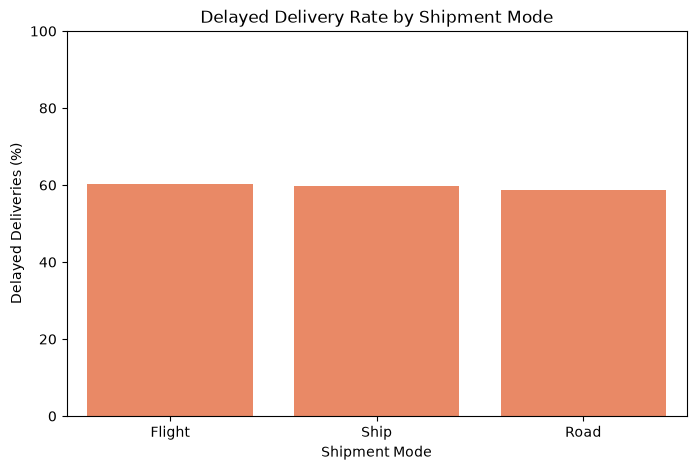

In [12]:
shipment_delay = (
    df.groupby("Mode_of_Shipment")["Reached.on.Time_Y.N"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(shipment_delay)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=shipment_delay.index,
    y=shipment_delay.values,
    color="coral"
)

plt.title("Delayed Delivery Rate by Shipment Mode")
plt.xlabel("Shipment Mode")
plt.ylabel("Delayed Deliveries (%)")
plt.ylim(0, 100)
plt.show()

Product_importance
high      64.978903
low       59.278837
medium    59.045015
Name: Reached.on.Time_Y.N, dtype: float64


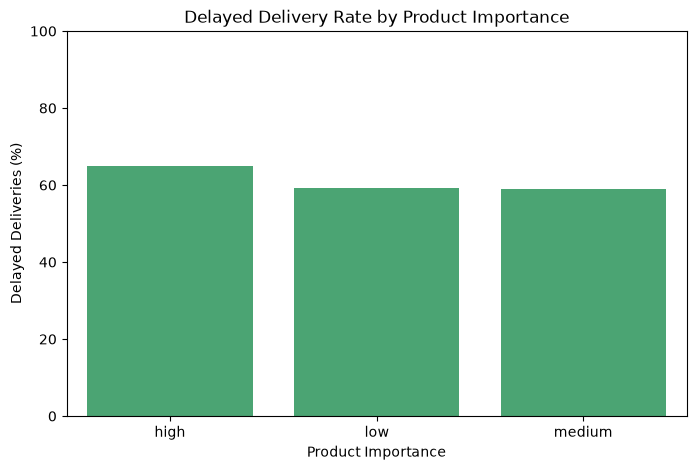

In [13]:
importance_delay = (
    df.groupby("Product_importance")["Reached.on.Time_Y.N"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(importance_delay)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=importance_delay.index,
    y=importance_delay.values,
    color="mediumseagreen"
)

plt.title("Delayed Delivery Rate by Product Importance")
plt.xlabel("Product Importance")
plt.ylabel("Delayed Deliveries (%)")
plt.ylim(0, 100)
plt.show()

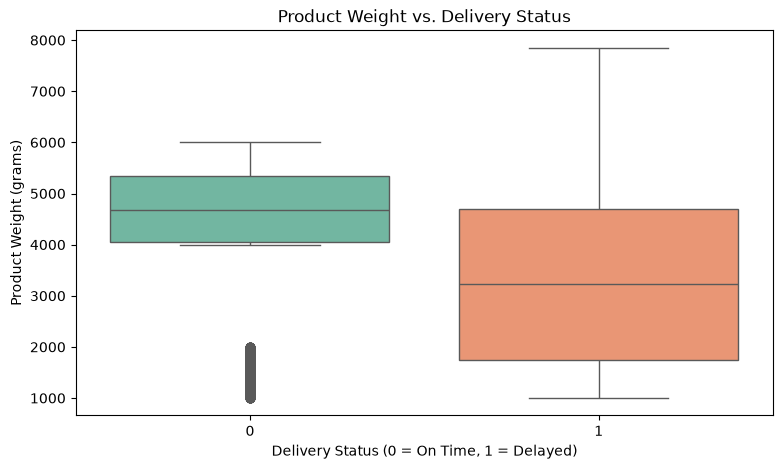

In [14]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Reached.on.Time_Y.N",
    y="Weight_in_gms",
    hue="Reached.on.Time_Y.N",
    palette="Set2",
    legend=False
)

plt.title("Product Weight vs. Delivery Status")
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Product Weight (grams)")
plt.show()

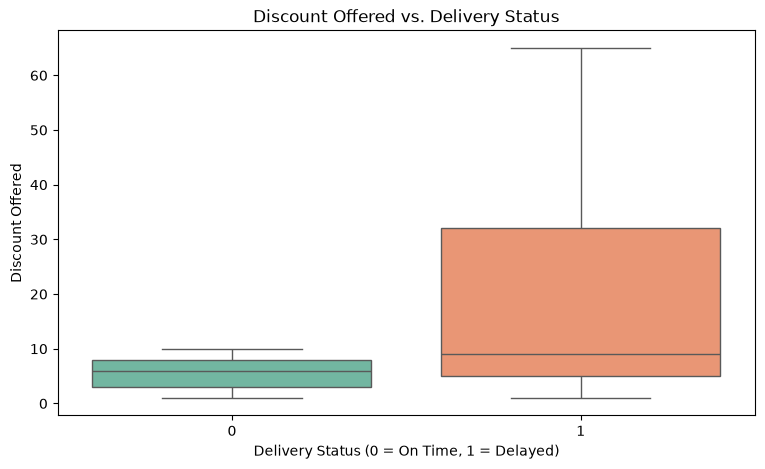

In [15]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Reached.on.Time_Y.N",
    y="Discount_offered",
    hue="Reached.on.Time_Y.N",
    palette="Set2",
    legend=False
)

plt.title("Discount Offered vs. Delivery Status")
plt.xlabel("Delivery Status (0 = On Time, 1 = Delayed)")
plt.ylabel("Discount Offered")
plt.show()

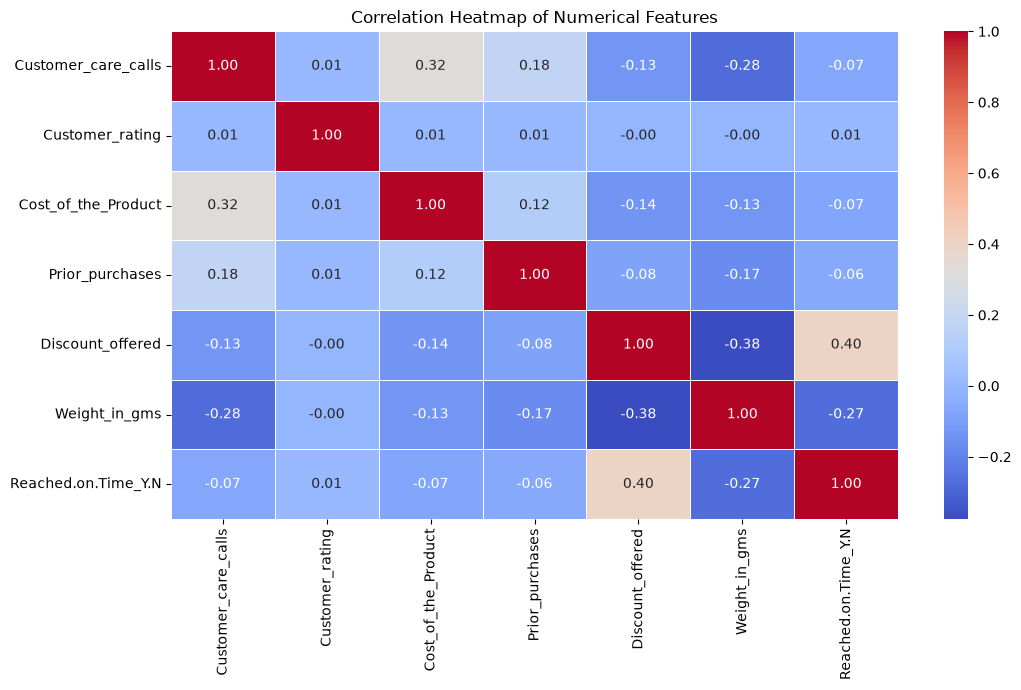

In [16]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 7))

sns.heatmap(
    numeric_df.drop(columns=["ID"], errors="ignore").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [17]:
target = "Reached.on.Time_Y.N"

correlations = (
    numeric_df
    .drop(columns=["ID"], errors="ignore")
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

print(correlations)

Discount_offered       0.397108
Weight_in_gms         -0.268793
Cost_of_the_Product   -0.073587
Customer_care_calls   -0.067126
Prior_purchases       -0.055515
Customer_rating        0.013119
Name: Reached.on.Time_Y.N, dtype: float64


In [19]:
target = "Reached.on.Time_Y.N"

df_sorted = df.sort_values("ID").reset_index(drop=True)

df_sorted["ID_Group"] = pd.qcut(
    df_sorted["ID"],
    q=4,
    labels=["Q1", "Q2", "Q3", "Q4"]
)

print(
    df_sorted.groupby(
        "ID_Group",
        observed=True
    )[target].agg(["count", "mean"])
)


          count      mean
ID_Group                 
Q1         2750  1.000000
Q2         2750  0.515273
Q3         2749  0.445253
Q4         2750  0.426182
